# Modelo v1 — DenseNet121, clasificación binaria de neumonía
Framework: **PyTorch** (torchvision trae DenseNet121 listo). Si se define otro framework, este notebook se porta.

## Bloque 0 — Entorno: Drive, GPU, rutas e hiperparámetros

In [2]:
# Bloque 0.1 — Montar Drive, imports, semilla y GPU
# Imports base (Drive, azar, torch, GPU): estado global que todo lo demás necesita.
# Lo específico (pandas, rutas, hiperparámetros...) se define en el bloque que lo usa.
from google.colab import drive
drive.mount('/content/drive')

import random
import numpy as np  # lo necesita np.random.seed de abajo

import torch

# Semilla fija: mismos números aleatorios en cada corrida (resultado repetible).
# Va aquí y no en otro bloque porque es ESTADO GLOBAL: rige el azar de TODO
# lo que viene después (mezclado de lotes en 1.3/3.2, pesos iniciales en 2.1).
# Moverla más abajo rompería la repetibilidad en silencio.
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# GPU: el entrenamiento corre ahí (mucho más rápido que CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('GPU disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nombre GPU:', torch.cuda.get_device_name(0))
else:
    print('AVISO: sin GPU el entrenamiento será muy lento. Actívala en Entorno > Cambiar tipo de ejecución.')
print('Dispositivo de trabajo:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu128
GPU disponible: True
Nombre GPU: Tesla T4
Dispositivo de trabajo: cuda


In [3]:
# Bloque 0.2 — Traer el ZIP del Drive al disco local
# Se copia 1 solo archivo seguido (rápido). Si ya está con igual tamaño, se reutiliza.
import shutil
import time
from pathlib import Path  # rutas locales y del Drive
from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)

DRIVE_DATASETS = Path('/content/drive/MyDrive/TESIS/DATASETS')

# El ZIP en Drive (nombre fijo, tal como se descargó de Kaggle)
ZIP_ORIGEN = DRIVE_DATASETS / 'rsna-pneumonia-detection-challenge.zip'
print(f'ZIP en Drive: {ZIP_ORIGEN.name} ({ZIP_ORIGEN.stat().st_size / 1e9:.2f} GB)')


def copiar_con_barra(origen, destino):
    """Copia 1 archivo grande mostrando barra, velocidad y tiempo estimado."""
    destino.parent.mkdir(parents=True, exist_ok=True)
    total = origen.stat().st_size
    t0 = time.time()
    with open(origen, 'rb') as f0, open(destino, 'wb') as f1, tqdm(total=total, unit='B', unit_scale=True, desc=f'   - {origen.name}') as barra:
        while True:
            trozo = f0.read(8 * 1024 * 1024)
            if not trozo:
                break
            f1.write(trozo)
            barra.update(len(trozo))
    shutil.copystat(origen, destino)
    print(f'   - copiado en {time.time() - t0:.0f} s.')


ZIP_LOCAL = Path('/content') / ZIP_ORIGEN.name
if ZIP_LOCAL.exists() and ZIP_LOCAL.stat().st_size == ZIP_ORIGEN.stat().st_size:
    print('ZIP ya está en local, se reutiliza.')
else:
    copiar_con_barra(ZIP_ORIGEN, ZIP_LOCAL)

ZIP en Drive: rsna-pneumonia-detection-challenge.zip (3.93 GB)


   - rsna-pneumonia-detection-challenge.zip: 100%|██████████| 3.93G/3.93G [02:12<00:00, 29.6MB/s]

   - copiado en 133 s.


In [13]:
# Bloque 0.3 — Descomprimir en local y traer los CSV de splits
# El ZIP trae su propia carpeta (rsna-pneumonia-detection-challenge/); se usa tal cual.
# Los splits ya vienen filtrados del Drive (test.ipynb); aquí solo se copian (pesan nada).
print('Descomprimiendo/actualizando en local (extrae solo lo que falte)...')
!unzip -uq '{ZIP_LOCAL}' -d '/content'
print(f'Listo en {time.time() - t0:.0f} s.')
FUENTE_IMGS = Path('/content/rsna-pneumonia-detection-challenge/stage_2_train_images')
if not FUENTE_IMGS.exists():
    # el ZIP trajo otra estructura: se ubica donde realmente quedó
    _cands = [p for p in Path('/content').rglob('stage_2_train_images') if p.is_dir()]
    assert len(_cands) > 0, 'No se halló stage_2_train_images tras descomprimir'
    FUENTE_IMGS = _cands[0]
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,} en {FUENTE_IMGS}')
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,}')

CARPETA_SPLITS = Path('/content/splits')  # aquí se copian los 3 CSV
CARPETA_SPLITS.mkdir(parents=True, exist_ok=True)
for _n in ['train.csv', 'val.csv', 'test.csv']:
    shutil.copy2(DRIVE_DATASETS / 'splits' / _n, CARPETA_SPLITS / _n)
print('Splits en:', CARPETA_SPLITS)

Descomprimiendo/actualizando en local (extrae solo lo que falte)...
Listo en 1066 s.
DICOMs locales: 26,684 en /content/stage_2_train_images
DICOMs locales: 26,684
Splits en: /content/splits


In [14]:
# Bloque 0.4 — Ruta de salida (los .npy que generará el 0.6)
CARPETA_NPY = Path('/content/dataset_filtrado')  # train/ val/ test/ con .npy
print('NPY:', CARPETA_NPY.exists(), '(False = aún no se corre el 0.6)')
print('Todo el trabajo corre en /content.')

NPY: True (False = aún no se corre el 0.6)
Todo el trabajo corre en /content.


In [15]:
# Bloque 0.5 — Funciones de transformación (solo se definen aquí, no procesan nada)
# Convierten 1 DICOM en 1 array (3,224,224) normalizado, en 4 pasos:
#   1. leer_dicom_como_gris: .dcm -> gris 0-255
#   2. redimensionar: 1024 -> 224
#   3. gris_a_rgb: 1 canal -> 3 canales
#   4. normalizar_imagenet: 0-255 -> escala ImageNet
# (Idénticas a las del Bloque 2 de test.ipynb; el 0.6 las aplica a todo.)

from PIL import Image  # aquí se redimensiona

# Media y desviación de ImageNet (las que espera DenseNet121 preentrenado).
# Se definen aquí porque solo se usan al normalizar.
MEDIA_IMAGENET = np.array([0.485, 0.456, 0.406], dtype=np.float32)
DESV_IMAGENET = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def leer_dicom_como_gris(ruta_dicom):
    """Paso 1: lee un .dcm y devuelve array uint8 de 0-255 en escala de grises."""
    import pydicom
    ds = pydicom.dcmread(str(ruta_dicom))
    img = ds.pixel_array
    if str(ds.get('PhotometricInterpretation', '')) == 'MONOCHROME1':
        img = 255 - img  # fondo negro -> fondo blanco (estándar radiológico)
    img = img.astype(np.float32)
    if img.max() > 255:  # por si algún DICOM trae 16 bits
        img = img / img.max() * 255.0
    return np.clip(img, 0, 255).astype(np.uint8)


def redimensionar(imagen_gris, tamano=224):
    """Paso 2: achica la imagen al tamaño que pide DenseNet121 (224x224)."""
    return np.array(Image.fromarray(imagen_gris).resize((tamano, tamano), Image.BILINEAR))


def gris_a_rgb(imagen_gris):
    """Paso 3: copia el gris en 3 canales RGB (0-1)."""
    rgb = np.stack([imagen_gris, imagen_gris, imagen_gris], axis=0)
    return rgb.astype(np.float32) / 255.0


def normalizar_imagenet(imagen_rgb):
    """Paso 4: ajusta los valores con media/desviación de ImageNet."""
    return (imagen_rgb - MEDIA_IMAGENET[:, None, None]) / DESV_IMAGENET[:, None, None]


def preprocesar_imagen(ruta_dicom, tamano=224):
    """Aplica los 4 pasos en orden: DICOM -> array (3, tamano, tamano) normalizado."""
    gris = leer_dicom_como_gris(ruta_dicom)
    gris_224 = redimensionar(gris, tamano)
    rgb = gris_a_rgb(gris_224)
    return normalizar_imagenet(rgb)


print('Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.')

Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.


In [16]:
# Bloque 0.6 — Generar los .npy en el disco local
# Recorre los 3 CSV y transforma SOLO lo que dicen (14,013 imágenes, no todo el ZIP).
# Muestra barra por split; si se cortó antes, continúa donde quedó (valida contenido, no solo existencia).
!pip install -q pydicom  # se instala aquí porque solo este bloque lee DICOMs
import pandas as pd  # aquí se leen los CSV de splits

def archivo_valido(ruta):
    """True si el .npy existe, pesa >0 y abre con forma (3,224,224)."""
    try:
        if not ruta.exists() or ruta.stat().st_size == 0:
            return False
        return np.load(ruta).shape == (3, 224, 224)
    except Exception:
        return False


def exportar_local():
    """Genera los .npy en disco local; regenera los vacíos o corruptos."""
    from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)
    for split in ['train', 'val', 'test']:
        df_split = pd.read_csv(CARPETA_SPLITS / f'{split}.csv')
        carpeta = CARPETA_NPY / split
        carpeta.mkdir(parents=True, exist_ok=True)
        # Verifica uno por uno: una interrupción deja archivos vacíos a medias
        pendientes = []
        for _, fila in tqdm(df_split.iterrows(), total=len(df_split), desc=f'   - verificar {split}'):
            if not archivo_valido(carpeta / f"{fila['patientId']}.npy"):
                pendientes.append(fila)
        print(f'   - {split}: {len(df_split):,} total | válidos {len(df_split) - len(pendientes):,} | a generar {len(pendientes):,}')
        for fila in tqdm(pendientes, desc=f'   - generar {split}'):
            arr = preprocesar_imagen(FUENTE_IMGS / f"{fila['patientId']}.dcm")
            np.save(carpeta / f"{fila['patientId']}.npy", arr)
        print(f'   - {split} OK en {carpeta}')


# Genera los .npy locales (solo transforma lo que dicen los CSV de splits).
exportar_local()

   - verificar train: 100%|██████████| 9808/9808 [00:00<00:00, 14380.32it/s]


   - train: 9,808 total | válidos 0 | a generar 9,808


   - generar train: 100%|██████████| 9808/9808 [02:11<00:00, 74.60it/s]


   - train OK en /content/dataset_filtrado/train


   - verificar val: 100%|██████████| 2102/2102 [00:00<00:00, 13585.32it/s]


   - val: 2,102 total | válidos 0 | a generar 2,102


... (2 outputs left out)

   - verificar test: 100%|██████████| 2103/2103 [00:00<00:00, 6808.03it/s]


   - test: 2,103 total | válidos 0 | a generar 2,103


   - generar test: 100%|██████████| 2103/2103 [00:27<00:00, 77.76it/s]

   - test OK en /content/dataset_filtrado/test


## Bloque 1 — Datos: CSV + .npy → cargadores

In [17]:
# Bloque 1.1 — Cargar los 3 CSV y verificar que todo calce
df_train = pd.read_csv(CARPETA_SPLITS / 'train.csv')
df_val = pd.read_csv(CARPETA_SPLITS / 'val.csv')
df_test = pd.read_csv(CARPETA_SPLITS / 'test.csv')

for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{nombre}: {len(df):,} filas | neumonía={df["etiqueta"].mean():.2%}')

# Verificación: cada fila del CSV debe tener su .npy en la carpeta que le toca
for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    n_npy = len(list((CARPETA_NPY / nombre).glob('*.npy')))
    print(f'{nombre}: {n_npy:,} archivos .npy')
    assert n_npy == len(df), f'Faltan .npy en {nombre} (corre el Bloque 0.6)'
print('Verificación OK: todo CSV tiene sus imágenes.')

train: 9,808 filas | neumonía=40.15%
val: 2,102 filas | neumonía=40.15%
test: 2,103 filas | neumonía=40.18%
train: 9,808 archivos .npy
val: 2,102 archivos .npy
test: 2,103 archivos .npy
Verificación OK: todo CSV tiene sus imágenes.


In [18]:
# Bloque 1.2 — Lector de datos: convierte cada fila del CSV en (imagen, etiqueta)
# El modelo no come archivos: esta clase carga el .npy y lo entrega como tensor.
from torch.utils.data import Dataset, DataLoader  # aquí se define el lector que los usa
class RadioDataset(Dataset):
    """Lee .npy (3,224,224) + etiqueta (0/1) a partir de un CSV de split."""
    def __init__(self, df, carpeta_npy):
        self.df = df.reset_index(drop=True)
        self.carpeta_npy = Path(carpeta_npy)

    def __len__(self):
        return len(self.df)  # cuántas imágenes hay

    def __getitem__(self, i):
        # i = número de fila: se busca su .npy y su etiqueta
        fila = self.df.iloc[i]
        imagen = torch.from_numpy(np.load(self.carpeta_npy / f"{fila['patientId']}.npy"))
        etiqueta = torch.tensor(float(fila['etiqueta']))
        return imagen, etiqueta

print('Clase RadioDataset definida (aún no lee nada, solo es el molde).')

Clase RadioDataset definida (aún no lee nada, solo es el molde).


In [19]:
# Bloque 1.3 — Armar los 3 cargadores y probar con un lote
# train se mezcla (shuffle) en cada época; val/test van en orden fijo.
BATCH = 32       # imágenes por lote: 32 cabe bien en la GPU gratis de Colab
TRABAJADORES = 2 # hilos que cargan imágenes mientras la GPU entrena
ds_train = RadioDataset(df_train, CARPETA_NPY / 'train')
ds_val = RadioDataset(df_val, CARPETA_NPY / 'val')
ds_test = RadioDataset(df_test, CARPETA_NPY / 'test')

en_gpu = (device.type == 'cuda')
cargar_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_val = DataLoader(ds_val, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_test = DataLoader(ds_test, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)

# Prueba: un lote del train. Forma esperada: (32 imágenes, 3 canales, 224, 224)
imagenes, etiquetas = next(iter(cargar_train))
print('Lote imágenes:', tuple(imagenes.shape), '| Lote etiquetas:', tuple(etiquetas.shape))
print('Etiquetas del lote:', etiquetas.int().tolist())
assert tuple(imagenes.shape[1:]) == (3, 224, 224), 'Forma inesperada en las imágenes'
print(f'Lotes por época -> train: {len(cargar_train)}, val: {len(cargar_val)}, test: {len(cargar_test)}')

Lote imágenes: (32, 3, 224, 224) | Lote etiquetas: (32,)
Etiquetas del lote: [1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1]
Lotes por época -> train: 307, val: 66, test: 66


## Bloque 2 — Modelo: DenseNet121 preentrenado + regla de aprendizaje

In [20]:
# Bloque 2.1 — Modelo v1: DenseNet121 preentrenado, adaptado a 1 salida
# Transfer learning en simple: el modelo ya sabe "ver" (aprendió con ImageNet)
# y solo se le cambia la última capa para que responda sí/no neumonía.
# (Los pesos se descargan solos la primera vez, ~30 MB.)
from torchvision import models  # aquí se crea el DenseNet121
import torch.nn as nn  # aquí se reemplaza su última capa
modelo = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# La última capa original responde 1000 clases de fotos; se reemplaza por 1 neurona
n_entradas = modelo.classifier.in_features
modelo.classifier = nn.Linear(n_entradas, 1)
modelo = modelo.to(device)

# Cuántos números va a ajustar el entrenamiento (parámetros entrenables)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f'DenseNet121 listo en {device} | parámetros a entrenar: {n_params:,}')
print('Última capa:', modelo.classifier)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 183MB/s]


DenseNet121 listo en cuda | parámetros a entrenar: 6,954,881
Última capa: Linear(in_features=1024, out_features=1, bias=True)


In [21]:
# Bloque 2.2 — Regla de aprendizaje: pérdida + optimizador
# Hay más "sin neumonía" que "con": pos_weight equilibra para que el modelo
# no aprenda el truco de responder siempre 0. Se calcula solo desde el train.
LR = 1e-4  # paso de aprendizaje: chico porque el modelo ya viene preentrenado
n_pos = int(df_train['etiqueta'].sum())
n_neg = len(df_train) - n_pos
peso_pos = torch.tensor([n_neg / n_pos], device=device)
print(f'Train: {n_pos:,} con neumonía / {n_neg:,} sin | peso positivo = {peso_pos.item():.3f}')

# Pérdida: castiga qué tan lejos quedó la respuesta de la etiqueta real
criterio = nn.BCEWithLogitsLoss(pos_weight=peso_pos)
# Optimizador: ajusta los parámetros un poquito tras cada lote (paso = LR)
optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
print('Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR =', LR)

Train: 3,938 con neumonía / 5,870 sin | peso positivo = 1.491
Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR = 0.0001


## Bloque 3 — Entrenamiento (guarda el mejor según val)

In [22]:
# Bloque 3.1 — Funciones de entrenamiento y evaluación (solo se definen aquí)
from sklearn.metrics import roc_auc_score
UMBRAL = 0.5  # probabilidad >= 0.5 cuenta como con neumonía (1). Lo usan evaluar (3.1), test (4.1) y casos (5.3).
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)

def entrenar_epoca(modelo, cargador):
    """Una vuelta completa al train: predice, mide error, corrige. Devuelve pérdida media."""
    modelo.train()
    perdidas = []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        optimizador.zero_grad()                # borra correcciones anteriores
        salidas = modelo(imagenes).squeeze(1)  # respuesta: 1 número por imagen
        perdida = criterio(salidas, etiquetas) # qué tan mal respondió
        perdida.backward()                     # calcula cómo corregir
        optimizador.step()                     # aplica la corrección
        perdidas.append(perdida.item())
    return float(np.mean(perdidas))


@torch.no_grad()  # aquí no se corrige nada, solo se mide (más rápido)
def evaluar(modelo, cargador):
    """Pasa val/test SIN corregir. Devuelve pérdida, exactitud y AUC."""
    modelo.eval()
    perdidas, todas_prob, todas_et = [], [], []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        salidas = modelo(imagenes).squeeze(1)
        perdidas.append(criterio(salidas, etiquetas).item())
        todas_prob.extend(torch.sigmoid(salidas).cpu().tolist())  # a probabilidad 0-1
        todas_et.extend(etiquetas.cpu().tolist())
    todas_prob = np.array(todas_prob)
    todas_et = np.array(todas_et)
    pred = (todas_prob >= UMBRAL).astype(int)
    acc = float((pred == todas_et).mean())
    auc = float(roc_auc_score(todas_et, todas_prob))
    return float(np.mean(perdidas)), acc, auc

print('Funciones entrenar_epoca y evaluar definidas.')

Funciones entrenar_epoca y evaluar definidas.


In [23]:
# Bloque 3.2 — Entrenamiento (celda larga: ~10 épocas en GPU)
# Solo se guarda el modelo que mejore el AUC en val (nunca se elige por train).
EPOCAS = 10  # vueltas completas al train: 10 bastan para el v1
CARPETA_MODELOS = Path('/content/drive/MyDrive/TESIS/MODELOS')  # aquí se guarda todo lo entrenado
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
# Cada época imprime su duración y cuánto falta aprox.
import time
# Cada corrida tiene su ID (fecha-hora): ningún archivo se sobrescribe entre corridas.
from datetime import datetime
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
# Cada corrida guarda en SU propia carpeta: nada se pisa entre corridas.
from datetime import datetime
mejor_auc = 0.0  # se compara solo dentro de ESTA corrida
CARPETA_CORRIDA = CARPETA_MODELOS / f'densenet121_v1_{RUN_ID}'
CARPETA_CORRIDA.mkdir(parents=True, exist_ok=True)
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'  # el mejor DE ESTA corrida
historial = []  # una fila por época: train_loss, val_loss, val_acc, val_auc

for epoca in range(1, EPOCAS + 1):
    t_ep = time.time()
    p_train = entrenar_epoca(modelo, cargar_train)
    p_val, acc_val, auc_val = evaluar(modelo, cargar_val)
    historial.append({'epoca': epoca, 'train_loss': p_train, 'val_loss': p_val, 'val_acc': acc_val, 'val_auc': auc_val})
    marca = ''
    if auc_val > mejor_auc:
        mejor_auc = auc_val
        torch.save(modelo.state_dict(), RUTA_MEJOR)
        marca = '  <-- GUARDADO (mejor AUC val)'
    dur = time.time() - t_ep
    eta_min = dur * (EPOCAS - epoca) / 60
    print(f'Época {epoca}/{EPOCAS} | train_loss={p_train:.4f} | val_loss={p_val:.4f} | val_acc={acc_val:.4f} | val_auc={auc_val:.4f} | {dur:.0f}s (~faltan {eta_min:.0f} min){marca}')

pd.DataFrame(historial).to_csv(CARPETA_CORRIDA / 'historial.csv', index=False)
print(f'\nMejor AUC val: {mejor_auc:.4f} | Modelo en: {RUTA_MEJOR}')
# La carpeta final lleva fecha + mejor AUC (ej: ..._20260909_153015_auc9865)
CARPETA_FINAL = CARPETA_MODELOS / f"densenet121_v1_{RUN_ID}_auc{str(round(mejor_auc, 4)).replace('0.', '')}"
CARPETA_CORRIDA.rename(CARPETA_FINAL)
CARPETA_CORRIDA = CARPETA_FINAL
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'
print(f'Carpeta de la corrida: {CARPETA_CORRIDA}')


Época 1/10 | train_loss=0.2444 | val_loss=0.2029 | val_acc=0.9320 | val_auc=0.9813 | 106s (~faltan 16 min)  <-- GUARDADO (mejor AUC val)
Época 2/10 | train_loss=0.1521 | val_loss=0.1649 | val_acc=0.9529 | val_auc=0.9865 | 111s (~faltan 15 min)  <-- GUARDADO (mejor AUC val)
Época 3/10 | train_loss=0.0979 | val_loss=0.2117 | val_acc=0.9505 | val_auc=0.9822 | 111s (~faltan 13 min)
Época 4/10 | train_loss=0.0522 | val_loss=0.2303 | val_acc=0.9415 | val_auc=0.9817 | 110s (~faltan 11 min)
Época 5/10 | train_loss=0.0400 | val_loss=0.2631 | val_acc=0.9386 | val_auc=0.9821 | 111s (~faltan 9 min)
Época 6/10 | train_loss=0.0301 | val_loss=0.2207 | val_acc=0.9486 | val_auc=0.9814 | 111s (~faltan 7 min)
Época 7/10 | train_loss=0.0194 | val_loss=0.3045 | val_acc=0.9429 | val_auc=0.9783 | 110s (~faltan 6 min)
Época 8/10 | train_loss=0.0198 | val_loss=0.3489 | val_acc=0.9196 | val_auc=0.9795 | 110s (~faltan 4 min)
Época 9/10 | train_loss=0.0304 | val_loss=0.2654 | val_acc=0.9410 | val_auc=0.9843 | 111

In [24]:
# Bloque 3.3 — Ver el historial época por época
df_hist = pd.DataFrame(historial)
print(df_hist.to_string(index=False))

 epoca  train_loss  val_loss  val_acc  val_auc
     1    0.244360  0.202872 0.931970 0.981342
     2    0.152081  0.164931 0.952902 0.986534
     3    0.097941  0.211675 0.950523 0.982186
     4    0.052156  0.230328 0.941484 0.981683
     5    0.040035  0.263069 0.938630 0.982093
     6    0.030096  0.220665 0.948620 0.981410
     7    0.019386  0.304507 0.942912 0.978269
     8    0.019790  0.348855 0.919600 0.979546
     9    0.030354  0.265413 0.941009 0.984301
    10    0.012723  0.293018 0.920552 0.982350


## Bloque 4 — Evaluación FINAL en test (una sola vez, al final)

In [25]:
# Bloque 4.1 — Medir el mejor modelo con datos que nunca vio entrenando
# Métricas de tesis: exactitud, AUC, sensibilidad, especificidad + matriz de confusión.
from sklearn.metrics import confusion_matrix, roc_auc_score
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)
import time as _time
_t0 = _time.time()

# Evalúa el mejor DE ESTA corrida. Para otra versión, cambia RUTA_MEJOR por su archivo.
modelo.load_state_dict(torch.load(RUTA_MEJOR, map_location=device))
modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for imagenes, etiquetas in tqdm(cargar_test, desc='   - lotes test', leave=False):
        salidas = modelo(imagenes.to(device)).squeeze(1)
        probs.extend(torch.sigmoid(salidas).cpu().tolist())
        reales.extend(etiquetas.tolist())
probs = np.array(probs)
reales = np.array(reales)
pred = (probs >= UMBRAL).astype(int)

acc = float((pred == reales).mean())
auc = float(roc_auc_score(reales, probs))
tn, fp, fn, tp = confusion_matrix(reales, pred).ravel()
sens = float(tp / (tp + fn))  # sensibilidad: de los enfermos, cuántos detectó
esp = float(tn / (tn + fp))   # especificidad: de los sanos, cuántos acertó

print(f'TEST (n={len(reales):,}) | exactitud={acc:.4f} | AUC={auc:.4f} | medido en {_time.time() - _t0:.0f} s')
print(f'Sensibilidad={sens:.4f} | Especificidad={esp:.4f} (umbral={UMBRAL})')
print('Matriz de confusión [filas=real, columnas=predicho]:')
print('                 pred 0     pred 1')
print(f'  real 0 (sano):  {tn:>6,}  {fp:>9,}')
print(f'  real 1 (neum):  {fn:>6,}  {tp:>9,}')

TEST (n=2,103) | exactitud=0.9415 | AUC=0.9852 | medido en 8 s
Sensibilidad=0.9432 | Especificidad=0.9404 (umbral=0.5)
Matriz de confusión [filas=real, columnas=predicho]:
                 pred 0     pred 1
  real 0 (sano):   1,183         75
  real 1 (neum):      48        797


In [26]:
# Bloque 4.2 — Guardar métricas y curvas en Drive (evidencia para la tesis)
import json  # aquí se guardan las métricas
import matplotlib
matplotlib.use('Agg')  # dibuja sin abrir ventanas (modo Colab)
import matplotlib.pyplot as plt

resultados = {
    'modelo': 'densenet121_v1', 'corrida': RUN_ID, 'epocas': EPOCAS, 'lr': LR, 'batch': BATCH,
    'umbral': UMBRAL, 'semilla': SEMILLA,
    'test_n': int(len(reales)),
    'exactitud': round(float(acc), 4), 'auc': round(float(auc), 4),
    'sensibilidad': round(float(sens), 4), 'especificidad': round(float(esp), 4),
    'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    'mejor_auc_val': round(float(mejor_auc), 4),
}
with open(CARPETA_CORRIDA / 'metricas.json', 'w') as f:
    json.dump(resultados, f, indent=2)

# Curvas: si val empeora mientras train mejora, hay sobreajuste (se reporta en tesis)
df_hist = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_hist['epoca'], df_hist['train_loss'], label='train')
ax[0].plot(df_hist['epoca'], df_hist['val_loss'], label='val')
ax[0].set_title('Pérdida por época')
ax[0].set_xlabel('época')
ax[0].legend()
ax[1].plot(df_hist['epoca'], df_hist['val_auc'], label='AUC val', color='green')
ax[1].plot(df_hist['epoca'], df_hist['val_acc'], label='Acc val', color='orange')
ax[1].set_title('Métricas val por época')
ax[1].set_xlabel('época')
ax[1].legend()
fig.tight_layout()
fig.savefig(CARPETA_CORRIDA / 'curvas.png', dpi=150)
print('Guardado en:', CARPETA_CORRIDA)
print(json.dumps(resultados, indent=2))

Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v1_20260914_173857_auc9865
{
  "modelo": "densenet121_v1",
  "corrida": "20260914_173857",
  "epocas": 10,
  "lr": 0.0001,
  "batch": 32,
  "umbral": 0.5,
  "semilla": 42,
  "test_n": 2103,
  "exactitud": 0.9415,
  "auc": 0.9852,
  "sensibilidad": 0.9432,
  "especificidad": 0.9404,
  "tn": 1183,
  "fp": 75,
  "fn": 48,
  "tp": 797,
  "mejor_auc_val": 0.9865
}


## Bloque 5 — Evaluación visual y extendida

Curvas, métricas de clasificación y prueba con pacientes al azar. Todo se guarda en Drive y se muestra aquí.

AUC=0.9852 | AP=0.9820 | Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v1_20260914_173857_auc9865/curvas_eval.png


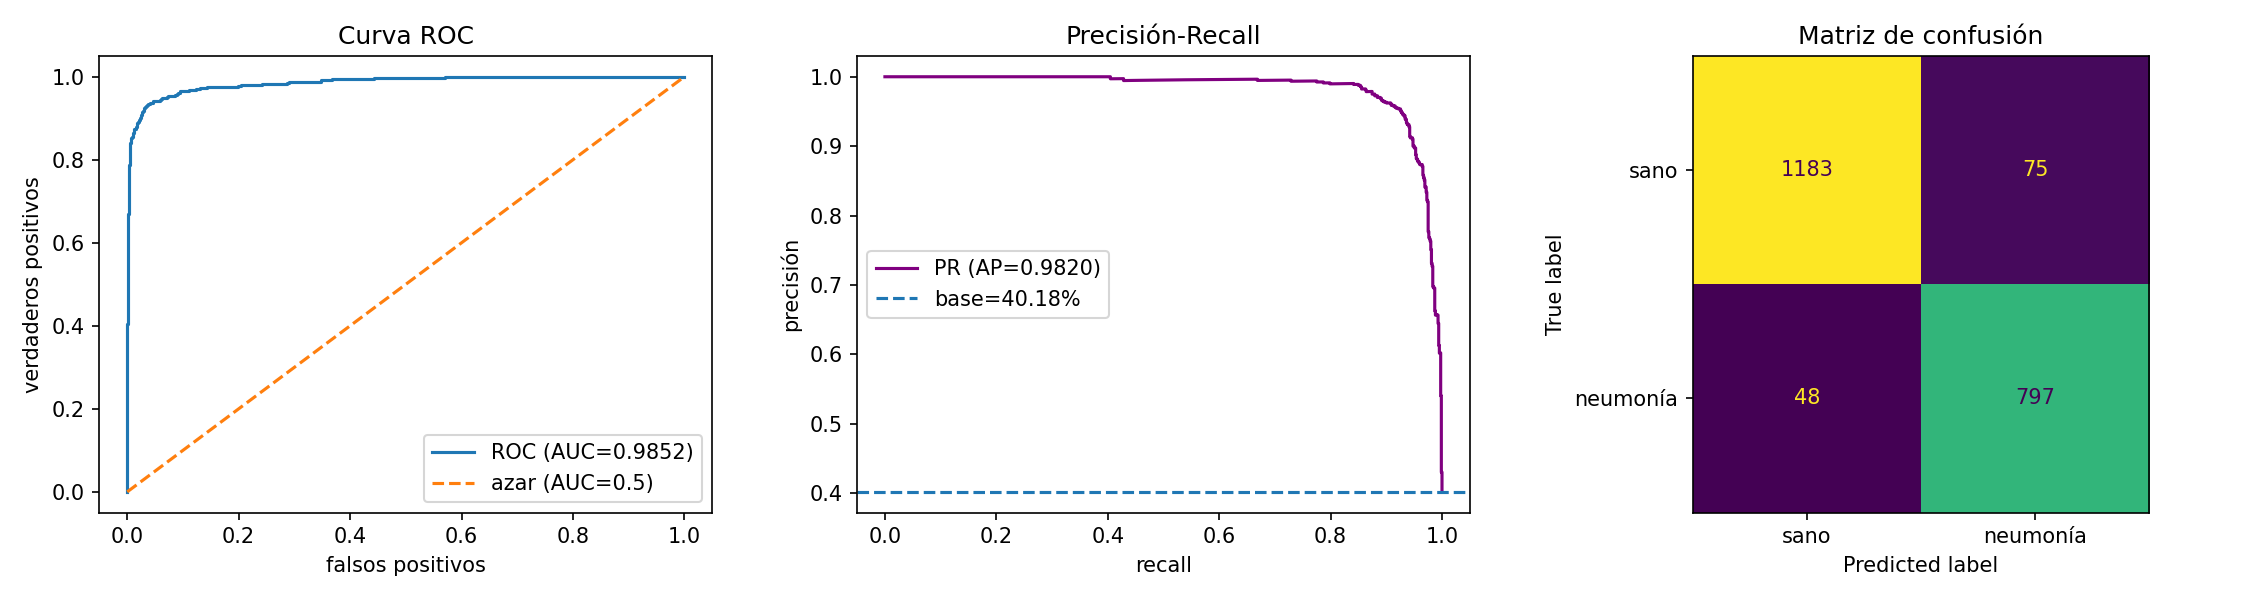

In [27]:
# Bloque 5.1 — Curvas ROC, precisión-recall y matriz de confusión
# Se guardan en Drive y se muestran aquí (display, no plt.show: vale en cualquier backend).
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

fpr, tpr, _ = roc_curve(reales, probs)  # ROC: qué tan bien separa sanos de enfermos
prec_c, rec_c, _ = precision_recall_curve(reales, probs)  # PR: útil con clases desbalanceadas
ap = float(average_precision_score(reales, probs))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(fpr, tpr, label=f'ROC (AUC={auc:.4f})')
ax[0].plot([0, 1], [0, 1], '--', label='azar (AUC=0.5)')
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('falsos positivos')
ax[0].set_ylabel('verdaderos positivos')
ax[0].legend()
ax[1].plot(rec_c, prec_c, label=f'PR (AP={ap:.4f})', color='purple')
ax[1].axhline(reales.mean(), linestyle='--', label=f'base={reales.mean():.2%}')
ax[1].set_title('Precisión-Recall')
ax[1].set_xlabel('recall')
ax[1].set_ylabel('precisión')
ax[1].legend()
ConfusionMatrixDisplay.from_predictions(reales, pred, display_labels=['sano', 'neumonía'], ax=ax[2], colorbar=False)
ax[2].set_title('Matriz de confusión')
fig.tight_layout()
RUTA_CURVAS_EVAL = CARPETA_CORRIDA / 'curvas_eval.png'
fig.savefig(RUTA_CURVAS_EVAL, dpi=150)
plt.close(fig)
print(f'AUC={auc:.4f} | AP={ap:.4f} | Guardada en: {RUTA_CURVAS_EVAL}')
display(MostrarImagen(str(RUTA_CURVAS_EVAL)))

In [28]:
# Bloque 5.2 — Métricas extendidas: precisión, recall, F1 y reporte por clase
# Precisión: de los que dijo 'sí', cuántos acertó. Recall (=sensibilidad): de los enfermos, cuántos detectó.
# F1: promedio de ambas (resume el equilibrio). Se imprimen y se guardan en JSON.
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import json as _json

precision = float(precision_score(reales, pred))
recall = float(recall_score(reales, pred))
f1 = float(f1_score(reales, pred))
print(f'Precisión={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f} | Especificidad={esp:.4f}')
print()
print(classification_report(reales, pred, target_names=['sano (0)', 'neumonía (1)'], digits=4))
ext = {'precision': round(precision, 4), 'recall': round(recall, 4), 'f1': round(f1, 4),
       'average_precision': round(float(ap), 4)}
with open(CARPETA_CORRIDA / 'metricas_extendidas.json', 'w') as f:
    _json.dump(ext, f, indent=2)
print('Guardadas en:', CARPETA_CORRIDA / 'metricas_extendidas.json')

Precisión=0.9140 | Recall=0.9432 | F1=0.9284 | Especificidad=0.9404

              precision    recall  f1-score   support

    sano (0)     0.9610    0.9404    0.9506      1258
neumonía (1)     0.9140    0.9432    0.9284       845

    accuracy                         0.9415      2103
   macro avg     0.9375    0.9418    0.9395      2103
weighted avg     0.9421    0.9415    0.9417      2103

Guardadas en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v1_20260914_173857_auc9865/metricas_extendidas.json


Aciertos en la muestra: 6/6

Detalle de la muestra:
#  paciente  real      predicho  prob.  resultado
1  9d5edce9  neumonía  neumonía  90%    ✓ acierto
2  b1831e52  neumonía  neumonía  74%    ✓ acierto
3  e43dfd99  sano      sano      5%     ✓ acierto
4  f06be57f  sano      sano      2%     ✓ acierto
5  a752bc48  sano      sano      0%     ✓ acierto
6  c252072c  neumonía  neumonía  100%   ✓ acierto
Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v1_20260914_173857_auc9865/casos_azar.png


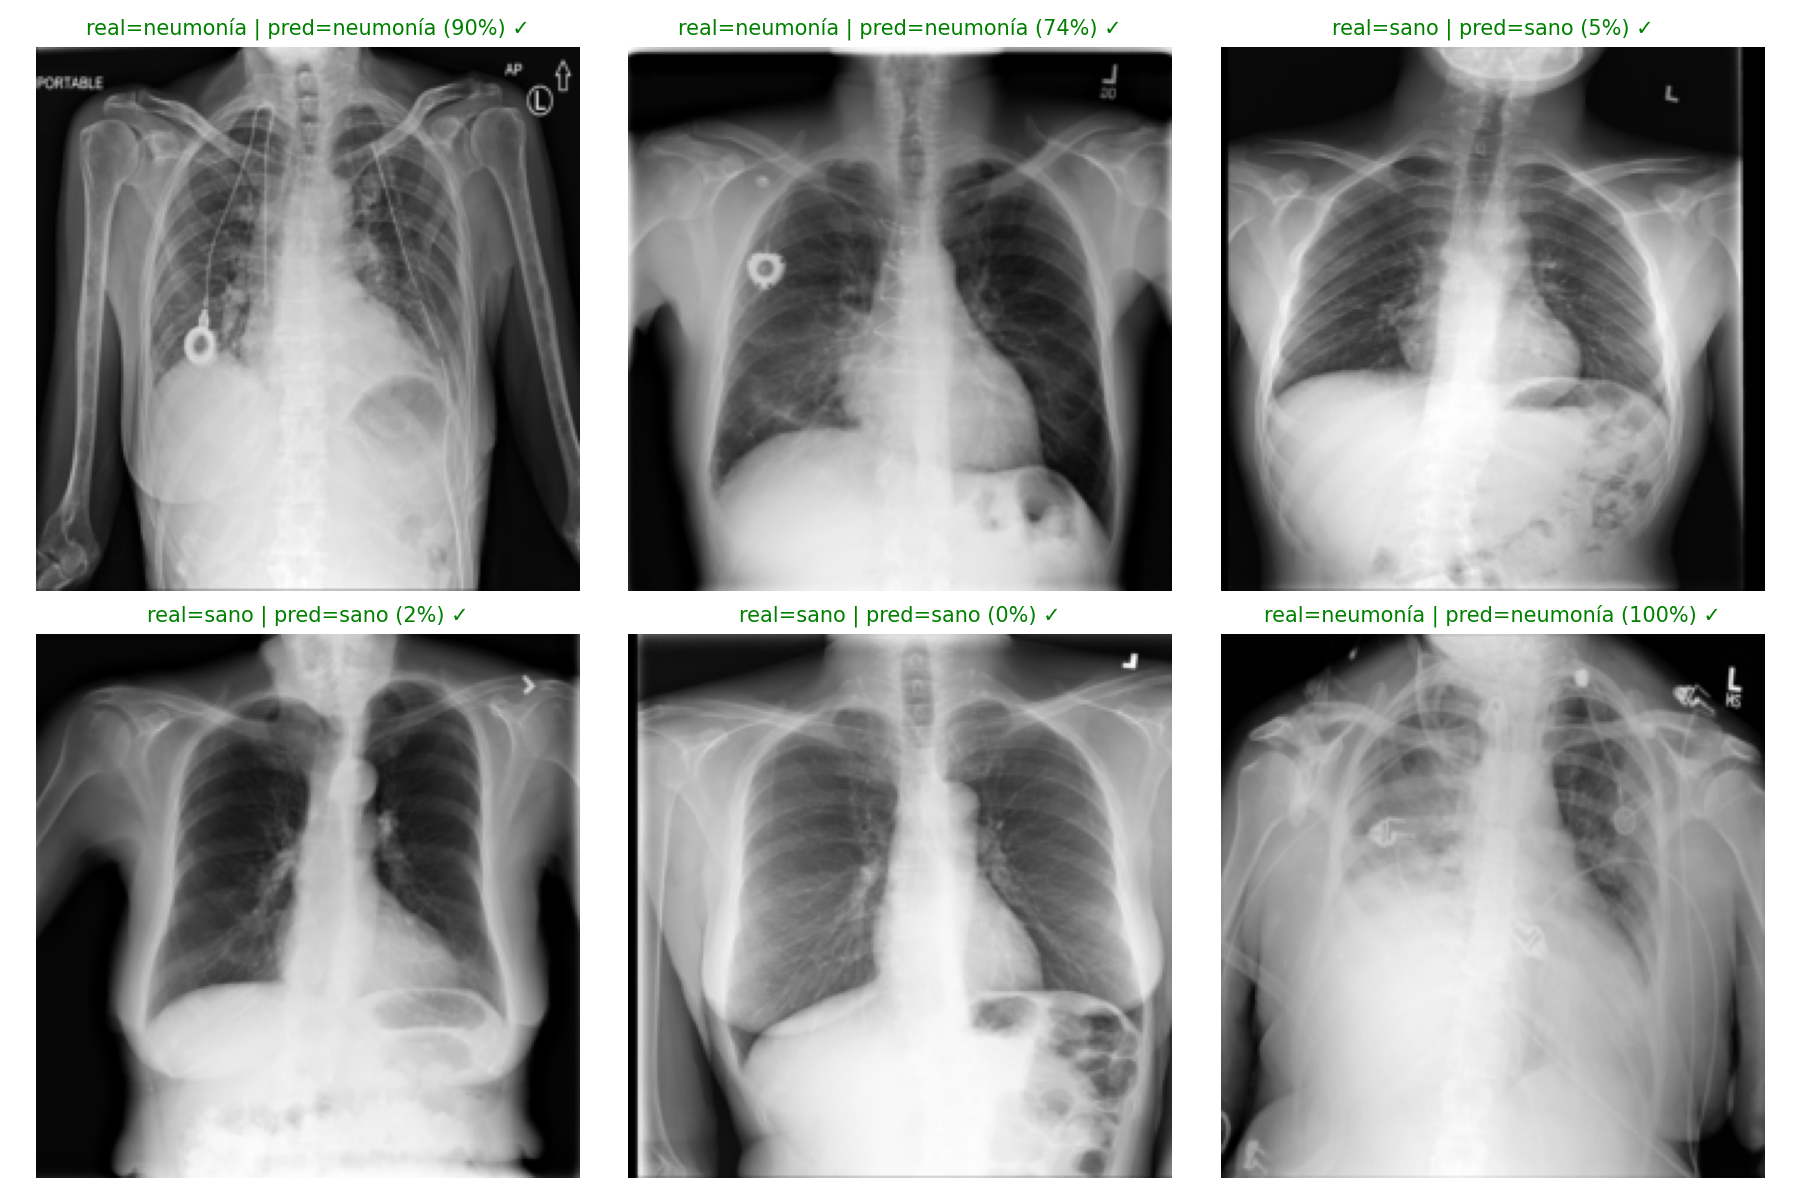

In [30]:
# Bloque 5.3 — Prueba con 6 pacientes al azar: ¿detecta bien?
# Muestra la radiografía con su etiqueta real y lo que predijo el modelo (verde=acierto, rojo=fallo).
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

def mostrar_gris(arr_norm):
    """Quita la normalización para ver la radiografía como gris 0-1."""
    img = arr_norm * DESV_IMAGENET[:, None, None] + MEDIA_IMAGENET[:, None, None]
    return np.clip(img[0], 0, 1)


rng = np.random.default_rng(7)  # semilla fija: siempre salen los mismos 6
idxs = rng.choice(len(df_test), size=6, replace=False)
filas = []  # para la tabla resumen (se imprime abajo)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.ravel(), idxs):
    pid = df_test.iloc[i]['patientId']
    arr = np.load(CARPETA_NPY / 'test' / f'{pid}.npy')
    ax.imshow(mostrar_gris(arr), cmap='gray')
    ax.axis('off')
    r, p = int(reales[i]), float(probs[i])
    bien = pred[i] == r
    filas.append((pid[:8], r, p >= UMBRAL, float(p), bool(bien)))
    ax.set_title(f"real={'neumonía' if r else 'sano'} | pred={'neumonía' if p >= UMBRAL else 'sano'} ({p:.0%}) {'✓' if bien else '✗'}",
                 color='green' if bien else 'red', fontsize=10)
fig.tight_layout()
RUTA_CASOS = CARPETA_CORRIDA / 'casos_azar.png'
fig.savefig(RUTA_CASOS, dpi=150)
plt.close(fig)
n_ok = int(sum(pred[i] == reales[i] for i in idxs))
print(f'Aciertos en la muestra: {n_ok}/6')
print('\nDetalle de la muestra:')
print(f"{'#':<3}{'paciente':<10}{'real':<10}{'predicho':<10}{'prob.':<7}resultado")
for k, (corto, r, pp, p, bien) in enumerate(filas, 1):
    print(f"{k:<3}{corto:<10}{'neumonía' if r else 'sano':<10}{'neumonía' if pp else 'sano':<10}{p:<7.0%}{'✓ acierto' if bien else '✗ fallo'}")
print('Guardada en:', RUTA_CASOS)
display(MostrarImagen(str(RUTA_CASOS)))